In [1]:
import numpy as np
import pandas as pd

In [11]:
df = pd.read_csv('1.csv')
t=df.Time.values
T =df.Thermocouple1.values
time = t.copy()
Te = T.copy()
print(t[843],T[843])
for i in range(len(t)):
    time[i]=t[i]-t[843]
    Te[i]=T[i]-T[843]

<class 'FileNotFoundError'>: [Errno 44] No such file or directory: '1.csv'

In [ ]:
import matplotlib.pyplot as plt
#plt.scatter(t[843:875], T[843:875], label='v2', color='orange')
terr=[]
Terr=[]
for i in range(32):
    terr.append(3)
    Terr.append(0.1)
print(terr)

plt.title('Thermocouple 1  increasing section')
plt.xlabel('Time (S)')
plt.ylabel('Temperature (K)')
plt.errorbar(time[843:875], Te[843:875], yerr=Terr, xerr=terr,fmt='o', color='orange')
plt.legend()

plt.savefig('GP49_2.png')

In [4]:
ds = 0.00001

In [5]:
from scipy.optimize import curve_fit
def fit1(tt, a, c):
    return c*(1-np.exp(-a * tt))

popt,pcov=curve_fit(fit1, time[843:875], Te[843:875], p0=None, sigma=ds)
print('a: ' +str(popt[0])+'    c:'+str(popt[1]))
print('Errors(a,c): '+ str(np.sqrt(np.diag(pcov))))
print(popt+1.959964*np.sqrt(pcov.diagonal()))
print(popt-1.959964*np.sqrt(pcov.diagonal()))

a: 0.01554254048023331    c:6.298689594499118
Errors(a,c): [0.00026279 0.06833749]
[0.0160576  6.43262861]
[0.01502748 6.16475058]


[3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
[0.         0.24002756 0.47092909 0.69298717 0.90667709 1.11218969
 1.30982978 1.49999441 1.68282429 1.85874908 2.02799606 2.1907653
 2.34729283 2.49789506 2.64278796 2.78212505 2.91613793 3.04502246
 3.16905306 3.2883392  3.40303239 3.51341339 3.61958464 3.72168554
 3.81987226 3.9143576  4.00523894 4.09263259 4.17670923 4.25760059
 4.33537415 4.41020007]


<ipython-input-10-62d633a65980>:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
<ipython-input-10-62d633a65980>:17: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig('GP49_fotted.png')
<ipython-input-10-62d633a65980>:17: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig('GP49_fotted.png')


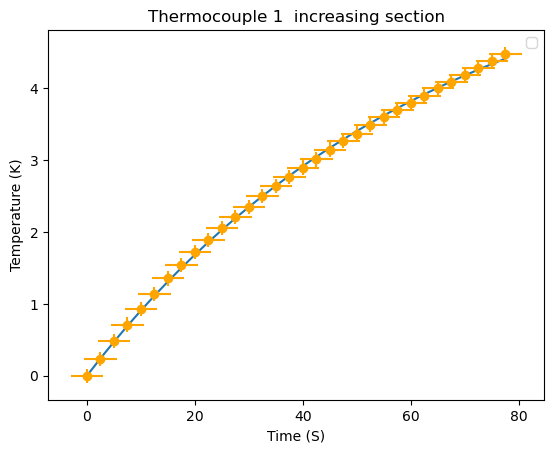

In [10]:
import matplotlib.pyplot as plt
#plt.scatter(t[843:875], T[843:875], label='v2', color='orange')
terr=[]
Terr=[]
for i in range(32):
    terr.append(3)
    Terr.append(0.1)
print(terr)
print(fit1(time,popt[0],popt[1])[843:875])
plt.title('Thermocouple 1  increasing section')
plt.xlabel('Time (S)')
plt.ylabel('Temperature (K)')
plt.plot(time[843:875], fit1(time,popt[0],popt[1])[843:875])
plt.errorbar(time[843:875], Te[843:875], yerr=Terr, xerr=terr,fmt='o', color='orange')
plt.legend()

plt.savefig('GP49_fotted.png')